Shape: (284807, 33)


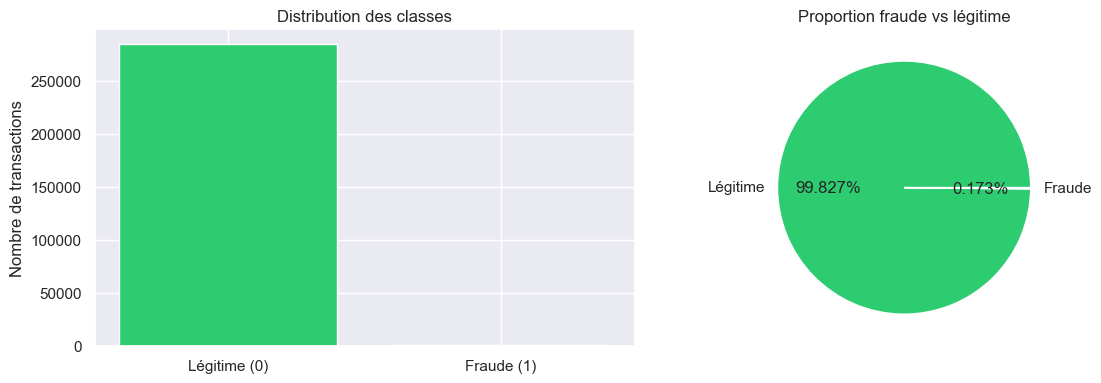

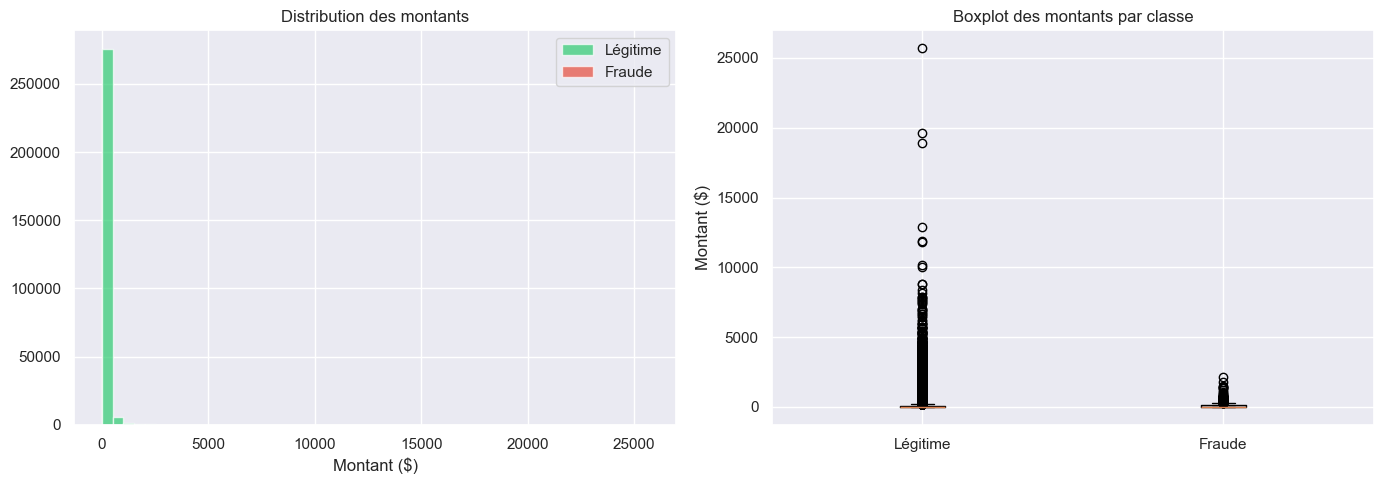

📊 STATISTIQUES CLÉS
Total transactions  : 284,807
Fraudes             : 492 (0.173%)
Montant moyen légit : $88.29
Montant moyen fraude: $122.21
Montant max fraude  : $2125.87


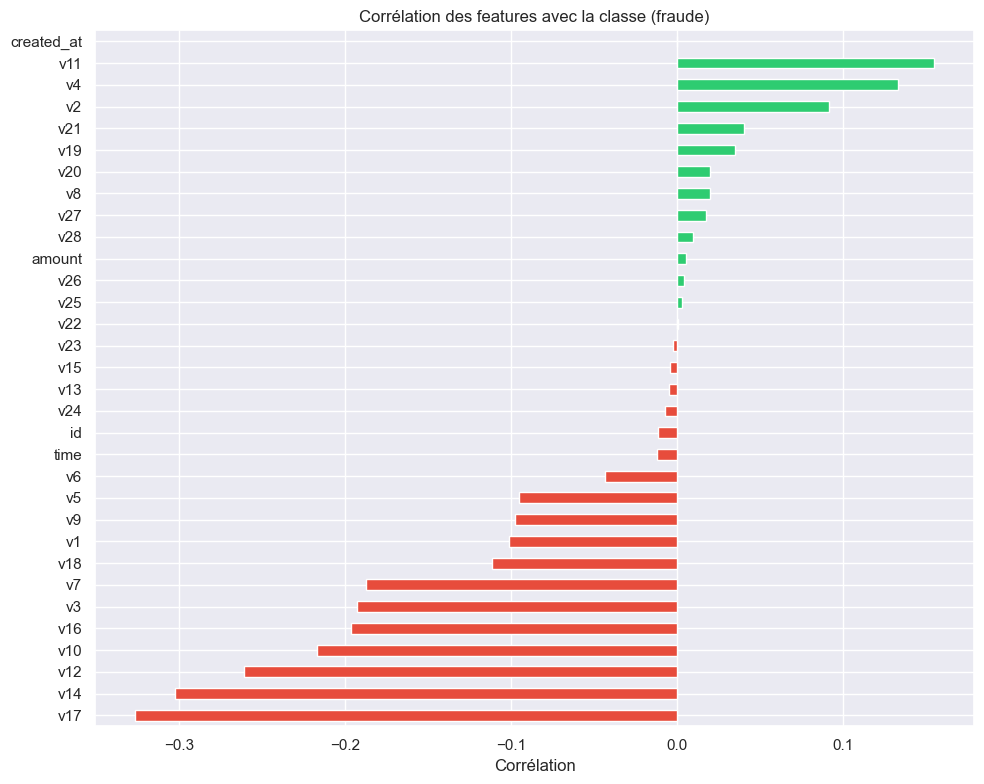

In [14]:
# Cellule 1 — Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from dotenv import load_dotenv
import os

load_dotenv(r"D:\fraud-detection-platform\.env")

engine = create_engine(
    f"postgresql+psycopg://"
    f"{os.getenv('POSTGRES_USER')}:{os.getenv('POSTGRES_PASSWORD')}"
    f"@{os.getenv('POSTGRES_HOST')}:{os.getenv('POSTGRES_PORT')}"
    f"/{os.getenv('POSTGRES_DB')}"
)

df = pd.read_sql("SELECT * FROM transactions", engine)

print(f"Shape: {df.shape}")
df.head()

# Cellule 3 — Distribution des classes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Comptage
class_counts = df['class'].value_counts()
axes[0].bar(['Légitime (0)', 'Fraude (1)'],
            class_counts.values,
            color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Distribution des classes')
axes[0].set_ylabel('Nombre de transactions')

# Pourcentage
axes[1].pie(class_counts.values,
            labels=['Légitime', 'Fraude'],
            colors=['#2ecc71', '#e74c3c'],
            autopct='%1.3f%%')
axes[1].set_title('Proportion fraude vs légitime')
plt.tight_layout()
plt.savefig('../data/processed/class_distribution.png', dpi=150)
plt.show()

# Cellule 4 — Distribution des montants
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fraud = df[df['class'] == 1]['amount']
legit = df[df['class'] == 0]['amount']

axes[0].hist(legit, bins=50, color='#2ecc71', alpha=0.7, label='Légitime')
axes[0].hist(fraud, bins=50, color='#e74c3c', alpha=0.7, label='Fraude')
axes[0].set_title('Distribution des montants')
axes[0].set_xlabel('Montant ($)')
axes[0].legend()

axes[1].boxplot([legit, fraud], labels=['Légitime', 'Fraude'])
axes[1].set_title('Boxplot des montants par classe')
axes[1].set_ylabel('Montant ($)')
plt.tight_layout()
plt.savefig('../data/processed/amount_distribution.png', dpi=150)
plt.show()

# Cellule 5 — Statistiques clés
print("=" * 50)
print("📊 STATISTIQUES CLÉS")
print("=" * 50)
print(f"Total transactions  : {len(df):,}")
print(f"Fraudes             : {df['class'].sum():,} ({df['class'].mean()*100:.3f}%)")
print(f"Montant moyen légit : ${legit.mean():.2f}")
print(f"Montant moyen fraude: ${fraud.mean():.2f}")
print(f"Montant max fraude  : ${fraud.max():.2f}")
print("=" * 50)

# Cellule 6 — Corrélation avec la classe
correlations = df.corr()['class'].drop('class').sort_values()
plt.figure(figsize=(10, 8))
correlations.plot(kind='barh', color=['#e74c3c' if x < 0 else '#2ecc71'
                                       for x in correlations])
plt.title('Corrélation des features avec la classe (fraude)')
plt.xlabel('Corrélation')
plt.tight_layout()
plt.savefig('../data/processed/correlations.png', dpi=150)
plt.show()